In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import seaborn as sns

In [3]:
df = pd.read_csv(r"../Data/dataset_wsn.csv")
df.sample(10)

,Date,Time,epoch,moteid,temperature,humidity,light,voltage
892488,22-03-2004,3:15:58 PM,31480,24,95.4974,43.1858,920.00,2.36622
236777,07-03-2004,3:44:10 PM,24812,7,26.1918,35.6456,264.96,2.65143
437118,08-03-2004,11:22:13 PM,28608,12,21.9484,38.1213,1.38,2.59354
654918,19-03-2004,12:42:19 PM,59008,19,122.1530,23.3435,235.52,2.31097
35663,16-03-2004,11:23:52 PM,51651,1,23.2224,33.0709,43.24,2.48502
364191,12-03-2004,10:04:04 AM,38532,10,21.8602,42.1830,625.60,2.52732
117740,25-03-2004,1:18:34 AM,38445,3,103.2000,42.3170,1.84,2.25825
716059,10-03-2004,3:03:02 AM,31930,21,22.4090,38.5311,3.68,2.57108
781532,12-03-2004,12:14:39 AM,37353,22,21.8602,38.3946,1.84,2.47467
812219,01-03-2004,9:22:52 AM,6770,23,24.8492,33.0709,264.96,2.71196


In [4]:
df.shape

(1048575, 8)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Date         1048575 non-null  object 
 1   Time         1048575 non-null  object 
 2   epoch        1048575 non-null  int64  
 3   moteid       1048575 non-null  int64  
 4   temperature  1048440 non-null  float64
 5   humidity     1048440 non-null  float64
 6   light        1025313 non-null  float64
 7   voltage      1048575 non-null  float64
dtypes: float64(4), int64(2), object(2)
memory usage: 64.0+ MB


In [6]:
df.isna().sum()

Date               0
Time               0
epoch              0
moteid             0
temperature      135
humidity         135
light          23262
voltage            0
dtype: int64

In [7]:
df["moteid"].nunique()

27

In [8]:
sorted(df["moteid"].dropna().unique())

[np.int64(1),
 np.int64(2),
 np.int64(3),
 np.int64(4),
 np.int64(5),
 np.int64(6),
 np.int64(7),
 np.int64(8),
 np.int64(9),
 np.int64(10),
 np.int64(11),
 np.int64(12),
 np.int64(13),
 np.int64(14),
 np.int64(15),
 np.int64(16),
 np.int64(17),
 np.int64(18),
 np.int64(19),
 np.int64(20),
 np.int64(21),
 np.int64(22),
 np.int64(23),
 np.int64(24),
 np.int64(25),
 np.int64(26),
 np.int64(27)]

In [9]:
sensor_cols = ["temperature", "humidity", "light", "voltage"]

In [10]:
df[sensor_cols].describe().round(2)

,temperature,humidity,light,voltage
count,1048440.00,1048440.00,1025313.00,1048575.00
mean,40.07,32.57,353.81,2.49
std,38.19,19.01,499.44,0.18
min,-38.40,-8983.13,0.00,0.02
25%,20.58,30.61,30.36,2.39
50%,22.51,38.46,128.80,2.54
75%,27.46,42.85,426.88,2.64
max,122.15,114.89,1847.36,3.16


## Train Test split

performing train test split before doing EDA to prevent data leakage. We don't want test set (which is part of the entire dataset) to influence EDA or any decisions on feature engineering.

In [15]:
df_raw = df.copy()
df_raw["datetime"] = pd.to_datetime(
    df_raw["Date"].astype(str) + " " + df_raw["Time"].astype(str),
    dayfirst=True,
    errors="coerce"
)

df_raw = df_raw.sort_values("datetime").reset_index(drop=True)
split_idx = int(len(df_raw) * 0.75)

df_train = df_raw.iloc[:split_idx].copy()
df_test= df_raw.iloc[split_idx:].copy()

In [16]:
df_train.sample(10)

,Date,Time,epoch,moteid,temperature,humidity,light,voltage,datetime
740249,17-03-2004,9:18:44 PM,54281,3,22.5462,38.9061,39.56,2.47467,2004-03-17 21:18:44
362076,07-03-2004,2:18:37 AM,23201,21,19.9884,43.3858,3.68,2.59354,2004-03-07 02:18:37
321952,06-03-2004,4:59:33 AM,20643,1,19.4494,42.7185,46.92,2.60491,2004-03-06 04:59:33
254245,04-03-2004,4:44:31 PM,16293,7,21.2624,39.0422,128.80,2.63964,2004-03-04 16:44:31
297964,05-03-2004,4:27:34 PM,19139,22,24.6434,35.1609,655.04,2.65143,2004-03-05 16:27:34
617645,13-03-2004,6:53:33 PM,42471,25,23.8202,38.7357,0.46,2.54901,2004-03-13 18:53:33
199127,03-03-2004,10:07:57 AM,12620,18,25.2608,25.6696,507.84,2.50599,2004-03-03 10:07:57
176268,02-03-2004,9:54:29 PM,11153,17,20.9586,28.8661,90.16,2.56000,2004-03-02 21:54:29
606451,13-03-2004,12:16:02 PM,41676,3,27.5932,33.3507,426.88,2.59354,2004-03-13 12:16:02
344147,06-03-2004,4:40:41 PM,22045,3,25.1432,35.5764,202.40,2.66332,2004-03-06 16:40:41


<h3 align="center" style="color:blue">Data Cleaning</h3>

In [17]:
df_train.shape

(786431, 9)

In [18]:
df_train.isna().sum()

Date               0
Time               0
epoch              0
moteid             0
temperature       62
humidity          62
light          16665
voltage            0
datetime           0
dtype: int64

In [19]:
sensor_cols = ["temperature", "humidity", "light", "voltage"]

missing = df_train[sensor_cols].isna().sum()

print("Missing values:")
print(missing)

print("\nMissing percentage:")
print((missing / len(df_train) * 100).round(3))

Missing values:
temperature       62
humidity          62
light          16665
voltage            0
dtype: int64

Missing percentage:
temperature    0.008
humidity       0.008
light          2.119
voltage        0.000
dtype: float64


In [29]:
print("Temperature below -40 or above 85:")
print(
    df_train.loc[
        (df_train["temperature"] < -40) |
        (df_train["temperature"] > 85),
        ["Date", "Time", "moteid", "temperature"]
    ].sample(20)
)


Temperature below -40 or above 85:
              Date         Time  moteid  temperature
781818  19-03-2004   8:40:49 AM      16      122.153
508833  10-03-2004   4:20:35 AM      18      122.153
764834  18-03-2004   8:07:25 PM      17      122.153
775623  19-03-2004   4:00:57 AM      16      122.153
780313  19-03-2004   7:34:49 AM      19      122.153
763272  18-03-2004   6:59:47 PM      17      122.153
744064  17-03-2004  11:46:24 PM      16      122.153
566028  12-03-2004  12:30:39 PM      18      122.153
748171  18-03-2004   2:14:54 AM      16      122.153
709094  17-03-2004   1:57:53 AM      17      122.153
761436  18-03-2004   5:37:22 PM      17      122.153
713684  17-03-2004   5:08:25 AM      17      122.153
571317  12-03-2004   3:32:30 PM      18      122.153
504002  10-03-2004   2:05:05 AM      18      122.153
526565  11-03-2004   1:38:18 PM      18      122.153
628683  14-03-2004   1:15:11 AM      18      122.153
573971  12-03-2004   5:04:39 PM      18      122.153
551161  12-

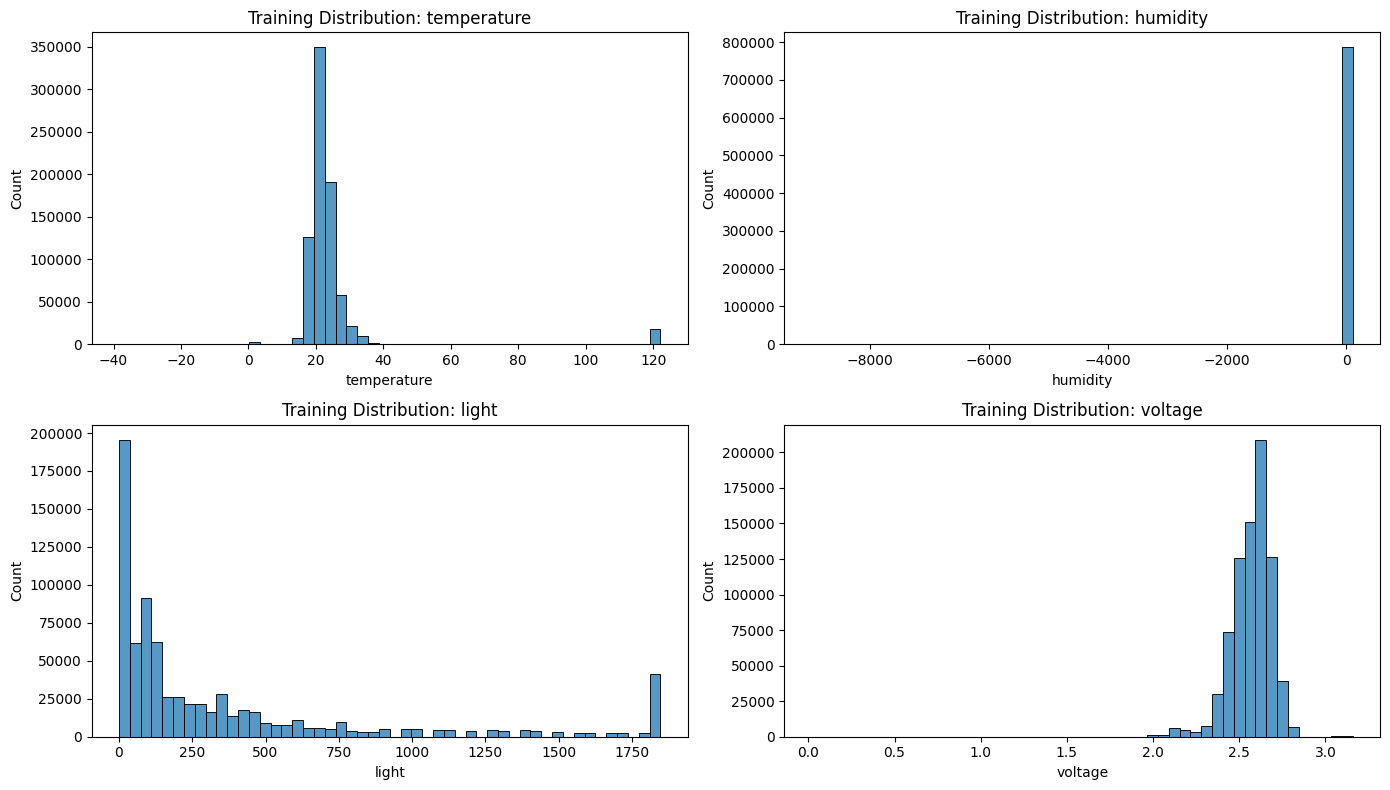

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for col, ax in zip(sensor_cols, axes.flatten()):
    sns.histplot(
        data=df_train,
        x=col,
        bins=50,
        kde=False,
        ax=ax
    )
    ax.set_title(f"Training Distribution: {col}")

plt.tight_layout()
plt.show()

Temperature: most readings are around 15–35°C, but there is a prominent spike near 122.153.


Humidity: the extreme negative value (around -8983) compresses nearly all other readings against zero in the histogram.


Light: the distribution is strongly right-skewed, with many low readings and a long upper tail. Zero may be a valid measurement.


Voltage: most readings cluster around 2.4–2.7 V, with a few lower values that deserve inspection.

In [31]:
# Inspect extreme readings without modifying the dataset
print("Temperature extremes:")
print(
    df_train.loc[
        (df_train["temperature"] < -40) |
        (df_train["temperature"] > 85),
        ["Date", "Time", "moteid", "temperature"]
    ].head(20)
)

print("\nHumidity extremes:")
print(
    df_train.loc[
        (df_train["humidity"] < 0) |
        (df_train["humidity"] > 100),
        ["Date", "Time", "moteid", "humidity"]
    ].head(20)
)

print("\nExact suspicious value counts:")
print("Temperature = 122.153:",
      (df_train["temperature"] == 122.153).sum())

print("Humidity = -8983.13:",
      (df_train["humidity"] == -8983.13).sum())

Temperature extremes:
              Date        Time  moteid  temperature
149688  02-03-2004  7:39:30 AM      15      122.153
149715  02-03-2004  7:40:23 AM      15      122.153
149737  02-03-2004  7:41:00 AM      15      122.153
149746  02-03-2004  7:41:23 AM      15      122.153
149842  02-03-2004  7:44:16 AM      15      122.153
149865  02-03-2004  7:44:58 AM      15      122.153
149872  02-03-2004  7:45:23 AM      15      122.153
149891  02-03-2004  7:45:59 AM      15      122.153
149953  02-03-2004  7:47:54 AM      15      122.153
150059  02-03-2004  7:51:30 AM      15      122.153
150120  02-03-2004  7:53:53 AM      15      122.153
150209  02-03-2004  7:56:29 AM      15      122.153
150273  02-03-2004  7:58:16 AM      15      122.153
150276  02-03-2004  7:58:20 AM      15      122.153
150342  02-03-2004  8:00:08 AM      15      122.153
150393  02-03-2004  8:01:43 AM      15      122.153
150432  02-03-2004  8:03:02 AM      15      122.153
150449  02-03-2004  8:03:30 AM      15    

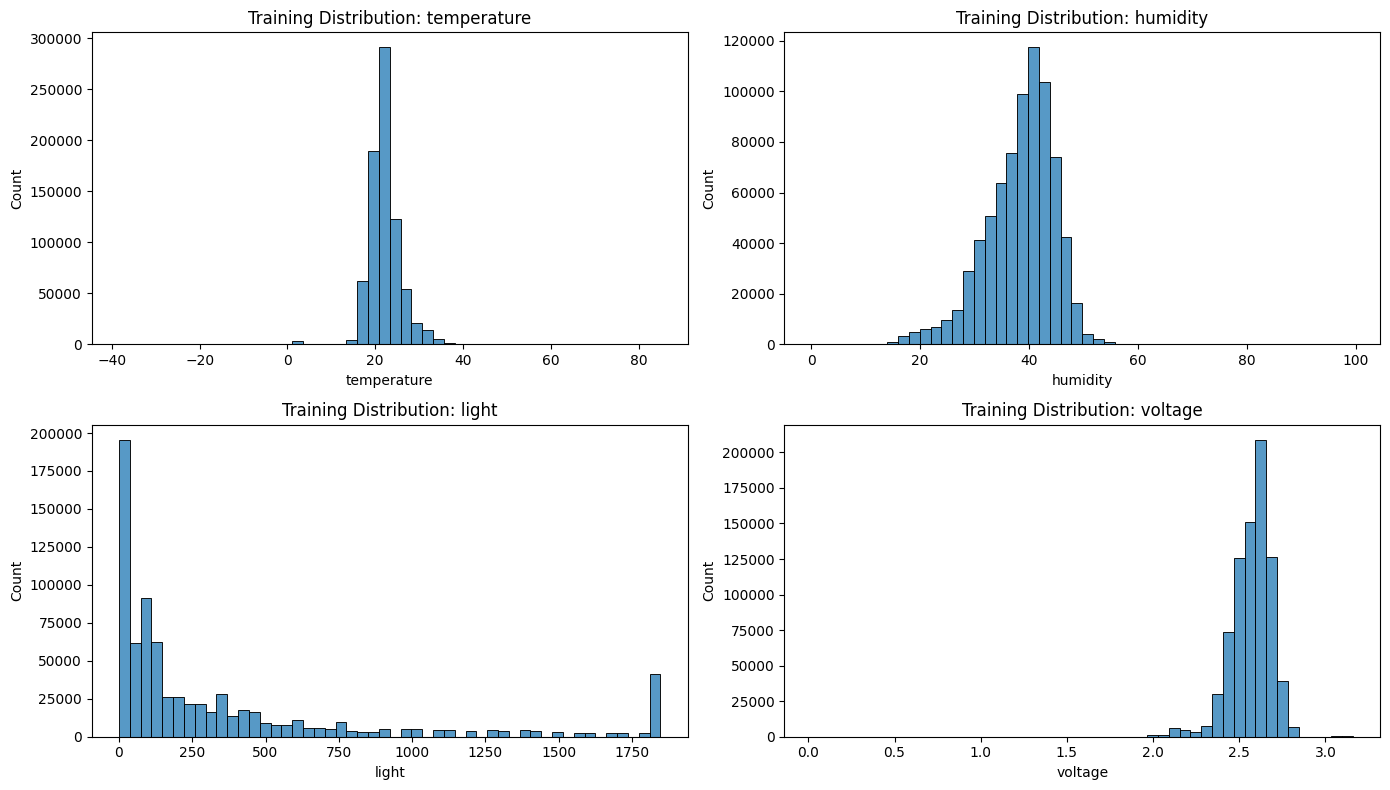

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

plot_data = df_train.copy()

# Temporary visualization filters only
plot_data.loc[
    (plot_data["temperature"] < -40) |
    (plot_data["temperature"] > 85),
    "temperature"
] = float("nan")

plot_data.loc[
    (plot_data["humidity"] < 0) |
    (plot_data["humidity"] > 100),
    "humidity"
] = float("nan")

for col, ax in zip(
    ["temperature", "humidity", "light", "voltage"],
    axes.flatten()
):
    sns.histplot(
        data=plot_data,
        x=col,
        bins=50,
        kde=False,
        ax=ax
    )
    ax.set_title(f"Training Distribution: {col}")

plt.tight_layout()
plt.show()

Temperature 122.153: appears 17,510 times and persists for sensor node 15 across consecutive readings. This could be a sensor fault, a dataset sentinel, or a recording issue; it should not automatically be classified as an attack.

Humidity -4.0: appears repeatedly, and -1854.52 is another extreme value. These require investigation and likely invalid-value handling after checking the dataset's encoding.

After temporary filtering for visualization: temperature and humidity show much more interpretable distributions. Light remains right-skewed, and voltage is concentrated around 2.5–2.7 V.

#### quantify suspicious values per sensor

To see whether the unusual values are concentrated in specific nodes

In [33]:
# Count suspicious measurements by sensor node
print("Temperature sentinel counts by node:")
print(
    df_train.loc[
        df_train["temperature"] == 122.153
    ].groupby("moteid").size().sort_values(ascending=False)
)

print("\nHumidity = -4 counts by node:")
print(
    df_train.loc[
        df_train["humidity"] == -4.0
    ].groupby("moteid").size().sort_values(ascending=False)
)

print("\nHumidity below zero by node:")
print(
    df_train.loc[
        df_train["humidity"] < 0
    ].groupby("moteid").size().sort_values(ascending=False)
)

Temperature sentinel counts by node:
moteid
18    8911
16    4051
17    3522
19     661
15     337
8       14
20      14
dtype: int64

Humidity = -4 counts by node:
moteid
18    1556
17     887
16     742
15     209
20      17
8       12
4        1
dtype: int64

Humidity below zero by node:
moteid
18    9589
16    3909
17    3480
15     216
19      61
20      17
8       13
2        1
4        1
dtype: int64


Node 18 has 8,911 temperature readings equal to 122.153 and 9,589 negative humidity readings. Nodes 16 and 17 also have substantial numbers of these readings.

### quantify the affected readings

In [34]:
node_stats = df_train.groupby("moteid").agg(
    total_readings=("moteid", "size"),
    invalid_temperature=("temperature",
                         lambda s: (s == 122.153).sum()),
    negative_humidity=("humidity",
                       lambda s: (s < 0).sum())
)

node_stats["temperature_invalid_pct"] = (
    100 * node_stats["invalid_temperature"]
    / node_stats["total_readings"]
)

node_stats["humidity_invalid_pct"] = (
    100 * node_stats["negative_humidity"]
    / node_stats["total_readings"]
)


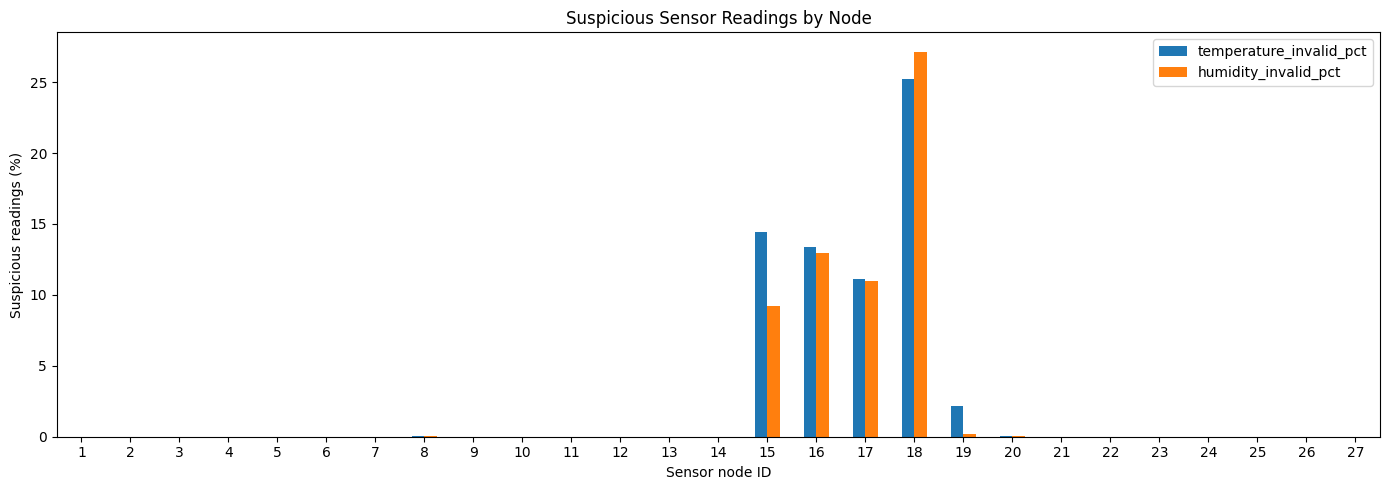

In [35]:

node_stats[
    ["temperature_invalid_pct", "humidity_invalid_pct"]
].plot(kind="bar", figsize=(14, 5))

plt.ylabel("Suspicious readings (%)")
plt.xlabel("Sensor node ID")
plt.title("Suspicious Sensor Readings by Node")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [37]:
import numpy as np
import pandas as pd

sensor_cols = [
    "temperature", "humidity", "light", "voltage"
]

def sensor_data(data):
    data = data.copy()

    # Preserve anomaly indicators for cause-aware analysis
    data["temperature_invalid"] = (
        data["temperature"] == 122.153
    ).astype("int8")

    data["humidity_invalid"] = (
        data["humidity"] < 0
    ).astype("int8")

    # Replace confirmed invalid measurements with missing values
    data.loc[
        data["temperature_invalid"] == 1,
        "temperature"
    ] = np.nan

    data.loc[
        data["humidity_invalid"] == 1,
        "humidity"
    ] = np.nan

    return data

df_train_clean = sensor_data(df_train)
df_test_clean = sensor_data(df_test)

# Learn imputation values from training data only
train_medians = df_train_clean[sensor_cols].median()

df_train_clean[sensor_cols] = (
    df_train_clean[sensor_cols].fillna(train_medians)
)

df_test_clean[sensor_cols] = (
    df_test_clean[sensor_cols].fillna(train_medians)
)

print("Training missing values:")
print(df_train_clean[sensor_cols].isna().sum())

print("\nTesting missing values:")
print(df_test_clean[sensor_cols].isna().sum())

Training missing values:
temperature    0
humidity       0
light          0
voltage        0
dtype: int64

Testing missing values:
temperature    0
humidity       0
light          0
voltage        0
dtype: int64


In [38]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(
    df_train_clean[sensor_cols]
).astype("float32")

X_test = scaler.transform(
    df_test_clean[sensor_cols]
).astype("float32")

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (786431, 4)
X_test: (262144, 4)


In [39]:
# X_train is already in chronological order
val_idx = int(len(X_train) * 0.85)

X_fit = X_train[:val_idx]
X_val = X_train[val_idx:]

print("Model training:", X_fit.shape)
print("Validation:", X_val.shape)

Model training: (668466, 4)
Validation: (117965, 4)


In [41]:
import tensorflow as tf
from tensorflow.keras import layers, Model

tf.keras.utils.set_random_seed(42)

inputs = layers.Input(shape=(X_fit.shape[1],))

x = layers.Dense(8, activation="relu")(inputs)
x = layers.Dense(3, activation="relu")(x)
x = layers.Dense(8, activation="relu")(x)

outputs = layers.Dense(X_fit.shape[1])(x)

autoencoder = Model(inputs, outputs)

autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

history = autoencoder.fit(
    X_fit,
    X_fit,
    validation_data=(X_val, X_val),
    epochs=30,
    batch_size=256,
    shuffle=False,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/30
2612/2612 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - loss: 0.3147 - val_loss: 0.3091
Epoch 2/30
2612/2612 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 0.0885 - val_loss: 0.1933
Epoch 3/30
2612/2612 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 0.0431 - val_loss: 0.1517
Epoch 4/30
2612/2612 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 0.0349 - val_loss: 0.1499
Epoch 5/30
2612/2612 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - loss: 0.0285 - val_loss: 0.1398
Epoch 6/30
2612/2612 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 0.0260 - val_loss: 0.1316
Epoch 7/30
2612/2612 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 0.0247 - val_loss: 0.1275
Epoch 8/30
2612/2612 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 0.0238 - val_loss: 0.1227
Epoch 9/30
2612/2612 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - loss: 0.0234 - val_loss: 0.1223
Epoch 10/30
2612/2612 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - loss: 0.0232 - val_loss: 0.1194
Epoch 11/30
2612/2612 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - loss: 0.0232 - val_loss: 0.1168
Epoch 12/30
2612/2612 ━━━━━━━━

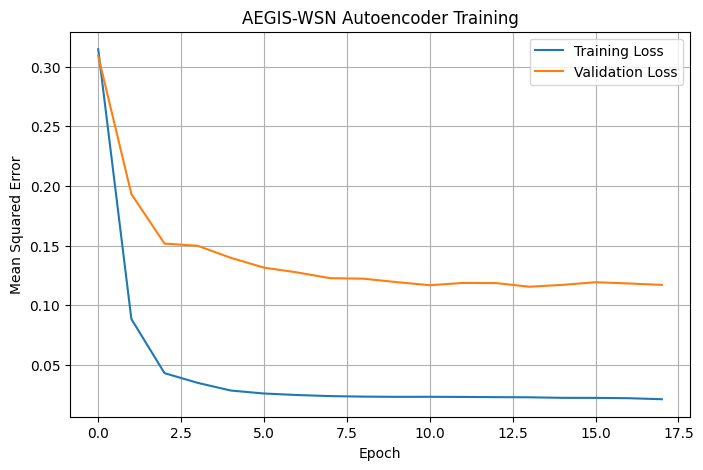

In [42]:

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("AEGIS-WSN Autoencoder Training")
plt.legend()
plt.grid(True)
plt.show()

In [43]:
best_epoch = np.argmin(history.history["val_loss"]) + 1
best_val_loss = min(history.history["val_loss"])

print("Epochs completed:", len(history.history["loss"]))
print("Best epoch:", best_epoch)
print("Best validation loss:", best_val_loss)

Epochs completed: 18
Best epoch: 14
Best validation loss: 0.11554460227489471


In [44]:
# Calculate validation reconstruction errors
val_reconstructed = autoencoder.predict(X_val, verbose=0)

val_scores = np.mean(
    (X_val - val_reconstructed) ** 2,
    axis=1
)

# Initial threshold based on validation errors
threshold = np.quantile(val_scores, 0.99)

print("Threshold:", threshold)
print("Validation readings:", len(val_scores))
print("Flagged validation readings:", (val_scores > threshold).sum())

Threshold: 2.4855628
Validation readings: 117965
Flagged validation readings: 1150


In [45]:
# Reconstruct test samples
test_reconstructed = autoencoder.predict(
    X_test,
    verbose=0
)

# Calculate reconstruction error for each test row
test_scores = np.mean(
    (X_test - test_reconstructed) ** 2,
    axis=1
)

# Apply the validation threshold
test_predictions = (
    test_scores > threshold
).astype(int)

print("Test readings:", len(test_predictions))
print("Flagged readings:", test_predictions.sum())

print(
    "Flagged percentage:",
    round(test_predictions.mean() * 100, 3),
    "%"
)

Test readings: 262144
Flagged readings: 26248
Flagged percentage: 10.013 %


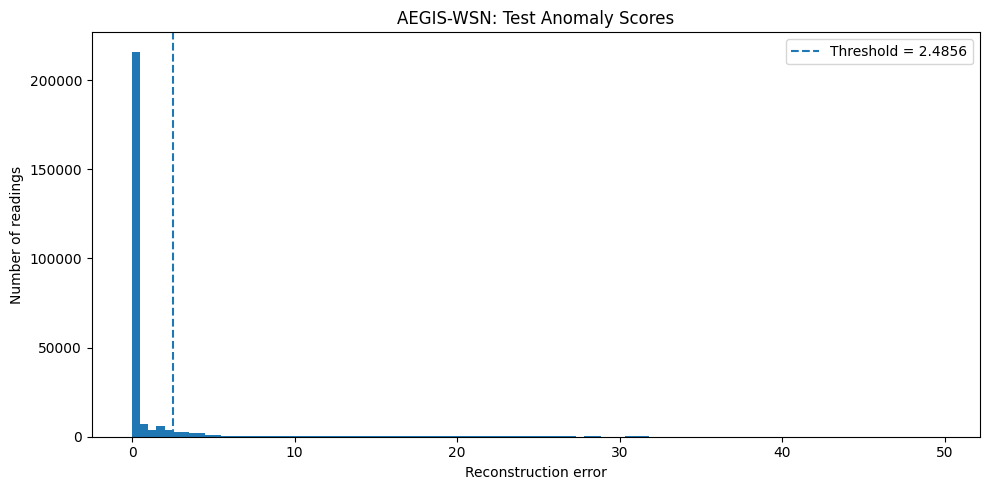

In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(test_scores, bins=100)
plt.axvline(
    threshold,
    linestyle="--",
    label=f"Threshold = {threshold:.4f}"
)

plt.xlabel("Reconstruction error")
plt.ylabel("Number of readings")
plt.title("AEGIS-WSN: Test Anomaly Scores")
plt.legend()
plt.tight_layout()
plt.show()

In [47]:
# Attach test predictions and scores to the corresponding test rows
test_results = df_test_clean.copy().reset_index(drop=True)

test_results["anomaly_score"] = test_scores
test_results["predicted_anomaly"] = test_predictions

print("Flagged readings by sensor node:")
print(
    test_results.groupby("moteid")["predicted_anomaly"]
    .agg(["count", "sum", "mean"])
    .assign(flagged_percentage=lambda x: x["mean"] * 100)
    .sort_values("flagged_percentage", ascending=False)
    .round(2)
)

Flagged readings by sensor node:
        count   sum  mean  flagged_percentage
moteid                                       
6        9865  2934  0.30               29.74
27         40    10  0.25               25.00
21      13612  2229  0.16               16.38
1       10600  1557  0.15               14.69
26      24551  3404  0.14               13.87
13       7795  1037  0.13               13.30
22      13727  1706  0.12               12.43
25      17045  1984  0.12               11.64
7       13963  1545  0.11               11.06
14       8619   911  0.11               10.57
2       15536  1535  0.10                9.88
12       5152   467  0.09                9.06
24      21042  1698  0.08                8.07
4       12786   854  0.07                6.68
23      20508  1356  0.07                6.61
9       13700   895  0.07                6.53
11      10196   655  0.06                6.42
3       13113   675  0.05                5.15
10      14885   649  0.04                4.36
1

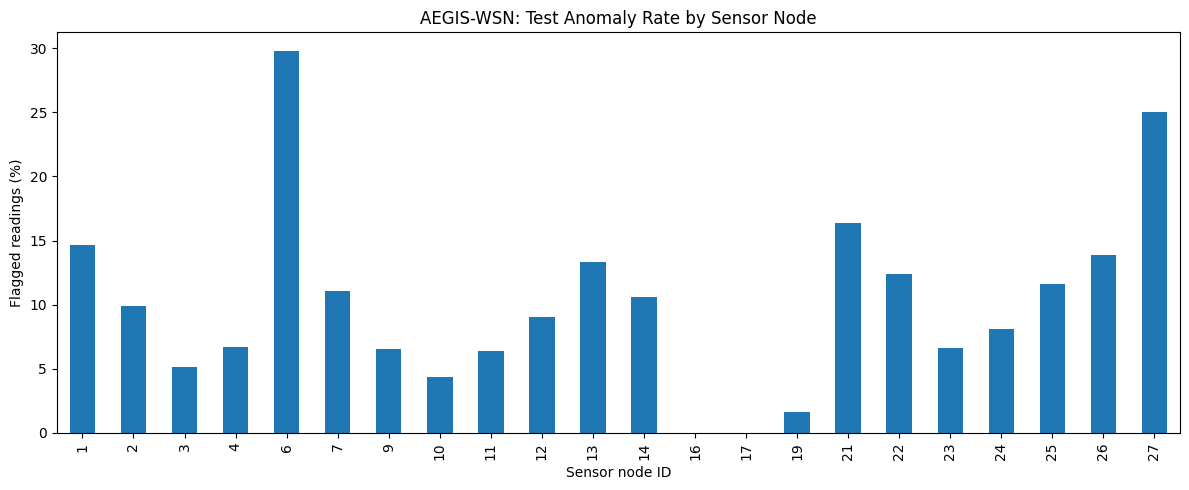

In [48]:
import matplotlib.pyplot as plt

node_flags = (
    test_results.groupby("moteid")["predicted_anomaly"]
    .mean()
    .mul(100)
    .sort_index()
)

node_flags.plot(kind="bar", figsize=(12, 5))

plt.ylabel("Flagged readings (%)")
plt.xlabel("Sensor node ID")
plt.title("AEGIS-WSN: Test Anomaly Rate by Sensor Node")
plt.tight_layout()
plt.show()

In [49]:
# Combine test anomaly scores and predictions with sensor metadata
test_results = df_test_clean.copy().reset_index(drop=True)

test_results["anomaly_score"] = test_scores
test_results["predicted_anomaly"] = test_predictions

# Preserve invalid-reading indicators
test_results["temperature_invalid"] = (
    test_results["temperature"] == 122.153
)

test_results["humidity_invalid"] = (
    test_results["humidity"] < 0
)

# Summarize each sensor node
node_analysis = test_results.groupby("moteid").agg(
    total_readings=("predicted_anomaly", "size"),
    flagged_readings=("predicted_anomaly", "sum"),
    temperature_invalid=("temperature_invalid", "sum"),
    humidity_invalid=("humidity_invalid", "sum"),
    mean_anomaly_score=("anomaly_score", "mean")
)

node_analysis["flagged_pct"] = (
    100 * node_analysis["flagged_readings"]
    / node_analysis["total_readings"]
)

node_analysis["temperature_invalid_pct"] = (
    100 * node_analysis["temperature_invalid"]
    / node_analysis["total_readings"]
)

node_analysis["humidity_invalid_pct"] = (
    100 * node_analysis["humidity_invalid"]
    / node_analysis["total_readings"]
)

print(
    node_analysis.sort_values(
        "flagged_pct", ascending=False
    ).round(2)
)

        total_readings  flagged_readings  temperature_invalid  \
moteid                                                          
6                 9865              2934                    0   
27                  40                10                    0   
21               13612              2229                    0   
1                10600              1557                    0   
26               24551              3404                    0   
13                7795              1037                    0   
22               13727              1706                    0   
25               17045              1984                    0   
7                13963              1545                    0   
14                8619               911                    0   
2                15536              1535                    0   
12                5152               467                    0   
24               21042              1698                    0   
4                12786   

In [50]:
sensor_cols = [
    "temperature", "humidity", "light", "voltage"
]

train_summary = (
    df_train_clean.groupby("moteid")[sensor_cols]
    .mean()
    .add_suffix("_train")
)

test_summary = (
    df_test_clean.groupby("moteid")[sensor_cols]
    .mean()
    .add_suffix("_test")
)

comparison = train_summary.join(test_summary, how="outer")

for col in sensor_cols:
    comparison[f"{col}_difference"] = (
        comparison[f"{col}_test"] - comparison[f"{col}_train"]
    )

print(comparison.round(3).head(27))

        temperature_train  humidity_train  light_train  voltage_train  \
moteid                                                                  
1                  21.960          37.891      161.532          2.602   
2                  21.993          39.862      209.529          2.558   
3                  22.066          38.207      148.167          2.601   
4                  22.066          38.954      158.857          2.566   
5                  21.821          39.416      128.800          2.516   
6                  22.056          39.246      436.309          2.538   
7                  21.639          38.876      130.106          2.596   
8                  21.243          38.112      651.737          2.646   
9                  21.602          39.911      734.669          2.658   
10                 21.324          40.488      230.972          2.586   
11                 20.843          42.002      518.155          2.547   
12                 20.413          42.489      407.

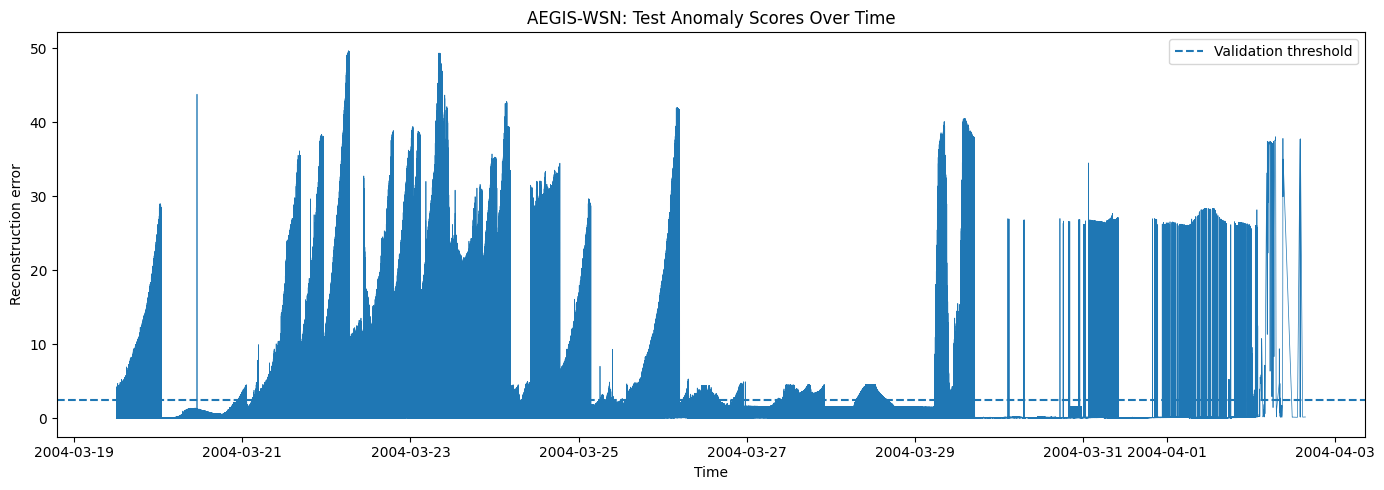

In [51]:
import matplotlib.pyplot as plt

test_results["datetime"] = pd.to_datetime(
    test_results["datetime"], errors="coerce"
)

test_results = test_results.sort_values("datetime")

plt.figure(figsize=(14, 5))

plt.plot(
    test_results["datetime"],
    test_results["anomaly_score"],
    linewidth=0.5
)

plt.axhline(
    threshold,
    linestyle="--",
    label="Validation threshold"
)

plt.xlabel("Time")
plt.ylabel("Reconstruction error")
plt.title("AEGIS-WSN: Test Anomaly Scores Over Time")
plt.legend()
plt.tight_layout()
plt.show()

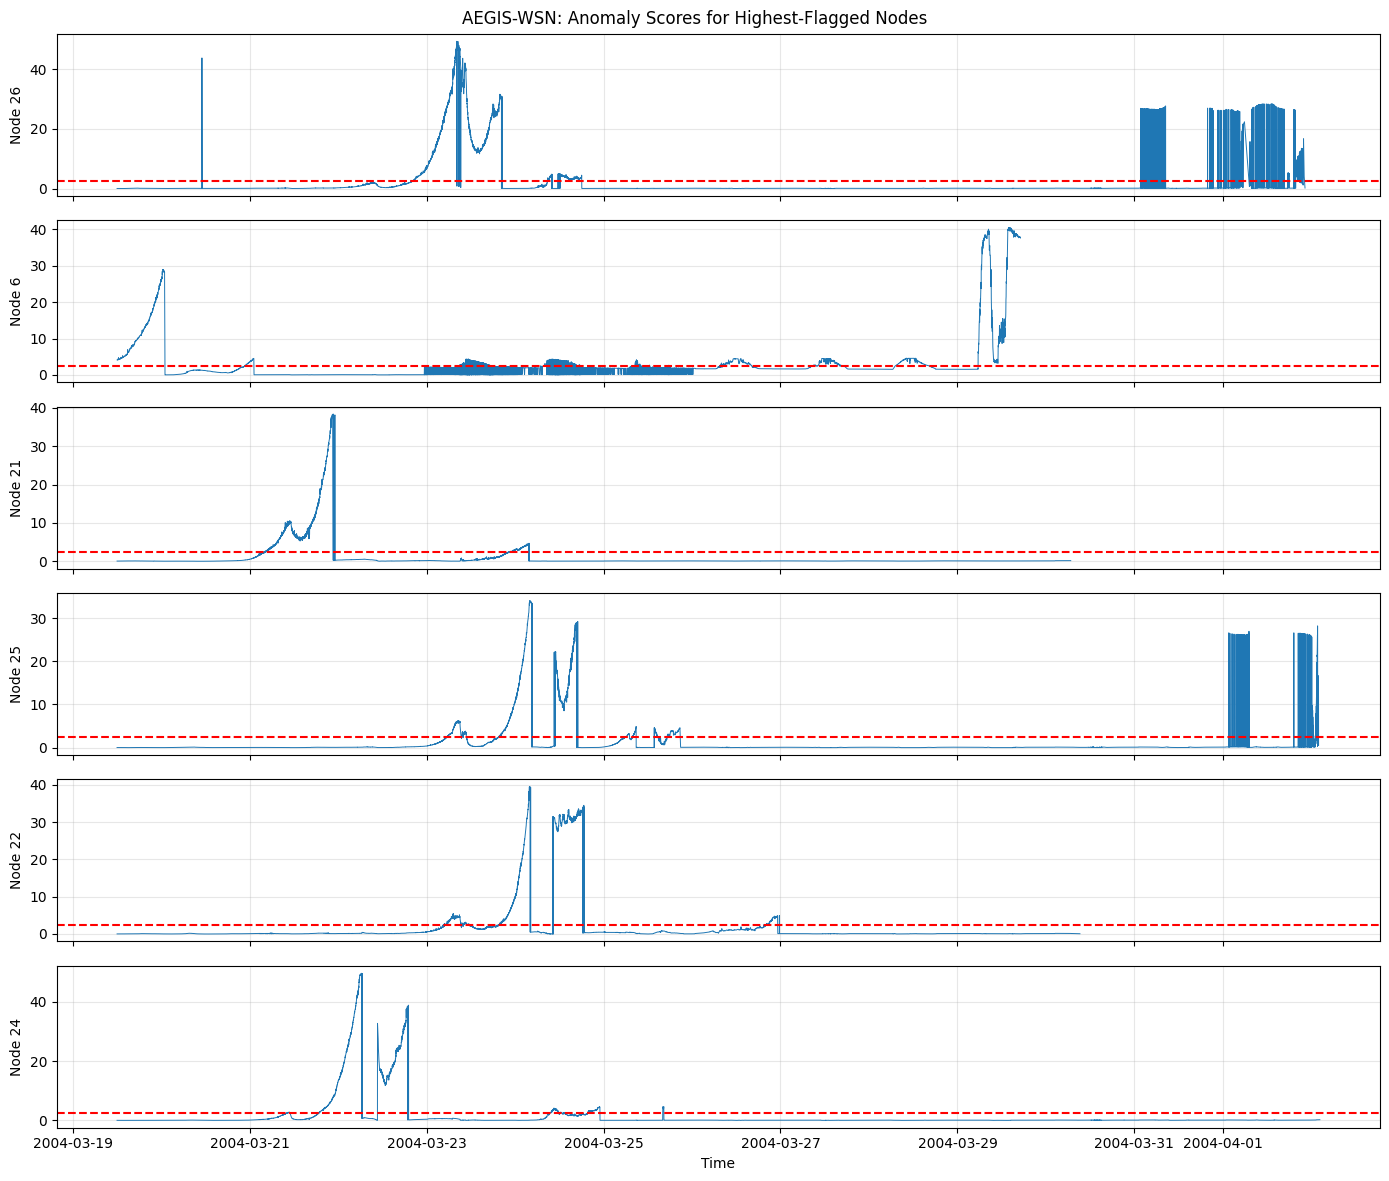

In [52]:
import matplotlib.pyplot as plt
import pandas as pd

# Ensure timestamps are parsed
test_results["datetime"] = pd.to_datetime(
    test_results["datetime"],
    errors="coerce"
)

# Plot the highest-activity nodes first
top_nodes = (
    test_results.groupby("moteid")["predicted_anomaly"]
    .sum()
    .nlargest(6)
    .index
)

fig, axes = plt.subplots(
    len(top_nodes), 1,
    figsize=(14, 12),
    sharex=True
)

for ax, node in zip(axes, top_nodes):
    node_data = test_results[
        test_results["moteid"] == node
    ].sort_values("datetime")

    ax.plot(
        node_data["datetime"],
        node_data["anomaly_score"],
        linewidth=0.7
    )

    ax.axhline(
        threshold,
        linestyle="--",
        color="red"
    )

    ax.set_ylabel(f"Node {node}")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time")
fig.suptitle("AEGIS-WSN: Anomaly Scores for Highest-Flagged Nodes")
plt.tight_layout()
plt.show()

In [53]:
# Count how many nodes are flagged within each 10-minute interval
test_results["time_window"] = (
    test_results["datetime"].dt.floor("10min")
)

simultaneous = (
    test_results[test_results["predicted_anomaly"] == 1]
    .groupby("time_window")["moteid"]
    .nunique()
    .sort_values(ascending=False)
)

print("Intervals with the most distinct flagged nodes:")
print(simultaneous.head(20))

Intervals with the most distinct flagged nodes:
time_window
2004-03-23 09:50:00    9
2004-03-23 09:40:00    9
2004-03-23 10:20:00    9
2004-03-23 08:30:00    9
2004-03-23 08:50:00    9
2004-03-23 09:00:00    9
2004-03-23 10:30:00    9
2004-03-23 10:40:00    9
2004-03-23 09:30:00    9
2004-03-23 08:10:00    8
2004-03-23 07:20:00    8
2004-03-23 10:10:00    8
2004-03-23 10:50:00    8
2004-03-23 11:30:00    8
2004-03-23 08:40:00    8
2004-03-23 08:20:00    8
2004-03-23 11:40:00    8
2004-03-23 10:00:00    8
2004-03-23 09:20:00    8
2004-03-23 11:20:00    8
Name: moteid, dtype: int64


In [54]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Focus on the high-anomaly period identified in your results
start = "2004-03-23 07:00:00"
end   = "2004-03-23 12:00:00"

period = test_results.loc[
    test_results["datetime"].between(start, end)
].copy()

# Inspect anomaly rates by node during this period
summary = period.groupby("moteid").agg(
    readings=("predicted_anomaly", "size"),
    flagged=("predicted_anomaly", "sum"),
    mean_score=("anomaly_score", "mean")
)

summary["flagged_pct"] = (
    summary["flagged"] / summary["readings"] * 100
)

print(summary.sort_values("flagged_pct", ascending=False).round(2))

        readings  flagged  mean_score  flagged_pct
moteid                                            
1            288      288    7.450000       100.00
2            294      294    7.340000       100.00
7            230      230    8.790000       100.00
14           218      218   25.260000       100.00
26           469      465   36.799999        99.15
25           492      357    3.640000        72.56
22           523      375    3.390000        71.70
6            217      105    2.030000        48.39
12            94       38    2.440000        40.43
3            372        0    0.090000         0.00
4            309        0    0.030000         0.00
13           151        0    0.040000         0.00
11           243        0    0.170000         0.00
10           172        0    0.040000         0.00
9            204        0    0.040000         0.00
21           512        0    0.140000         0.00
19           441        0    0.070000         0.00
24           539        0    0.

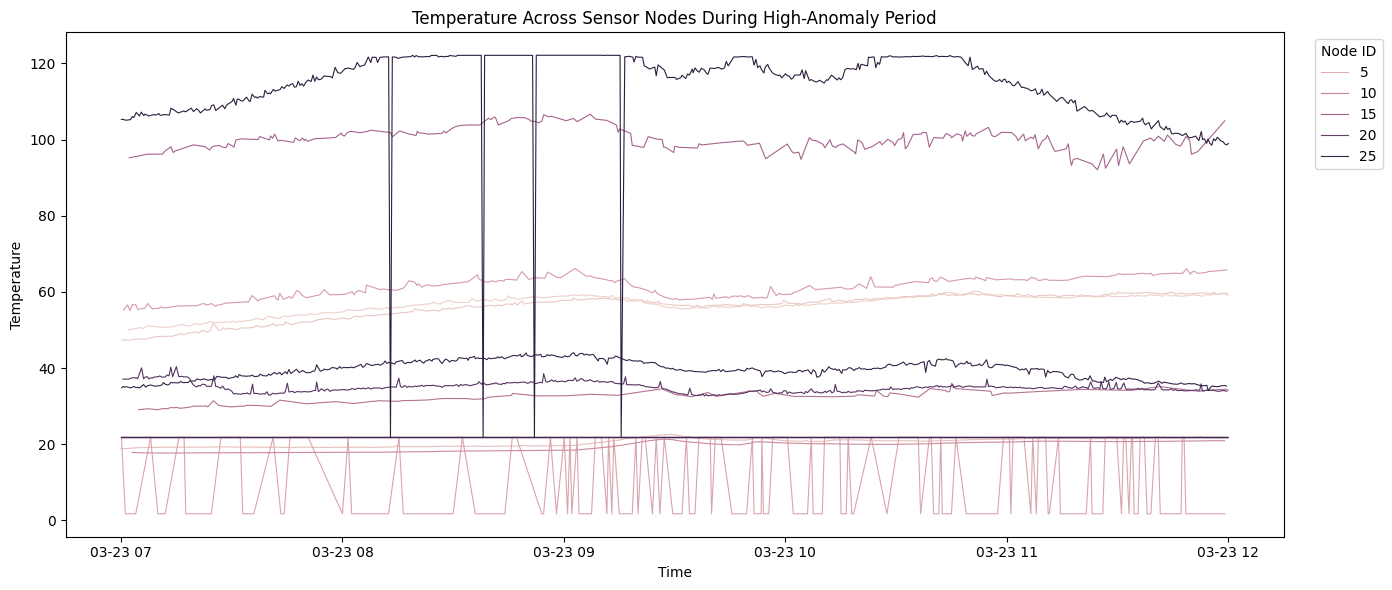

In [55]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=period,
    x="datetime",
    y="temperature",
    hue="moteid",
    estimator=None,
    linewidth=0.8
)

plt.title("Temperature Across Sensor Nodes During High-Anomaly Period")
plt.xlabel("Time")
plt.ylabel("Temperature")
plt.legend(title="Node ID", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [56]:
# Inspect the original records during the suspicious period
raw_period = df_test_raw.copy()

raw_period["datetime"] = pd.to_datetime(
    raw_period["datetime"],
    errors="coerce"
)

raw_period = raw_period.loc[
    raw_period["datetime"].between(
        "2004-03-23 07:00:00",
        "2004-03-23 12:00:00"
    )
]

print(
    raw_period.loc[
        (raw_period["temperature"] > 80) |
        (raw_period["temperature"] < 5),
        ["datetime", "moteid", "temperature",
         "humidity", "light", "voltage"]
    ].sort_values("datetime").head(50)
)

                  datetime  moteid  temperature  humidity  light  voltage
885554 2004-03-23 07:00:00      24     122.1530  51.85700  20.24  2.27556
885555 2004-03-23 07:00:00      11     122.1530  47.08130  57.04  2.22442
885556 2004-03-23 07:00:01      23     122.1530  42.68500   6.90  2.27556
885558 2004-03-23 07:00:05      21     122.1530  37.29930   9.20  2.22442
885559 2004-03-23 07:00:07      13     122.1530  34.39690  53.36  2.23278
885560 2004-03-23 07:00:07      26     105.2780  53.44270  21.16  2.27556
885561 2004-03-23 07:00:08       6     122.1530  -3.91901  37.72  2.18353
885563 2004-03-23 07:00:13       4     122.1530  -3.91901  13.80  2.24121
885564 2004-03-23 07:00:14      19     122.1530  -3.91901   8.28  2.16759
885567 2004-03-23 07:00:30      23     122.1530  42.78530   6.90  2.27556
885570 2004-03-23 07:00:30      24     122.1530  52.04800  21.16  2.28431
885571 2004-03-23 07:00:32      19     122.1530  -3.91901   8.28  2.16759
885573 2004-03-23 07:00:36      26    

In [57]:

rng = np.random.default_rng(42)

X_experiment = X_test.copy().astype(np.float32)
y_true = np.zeros(len(X_experiment), dtype=np.int32)

n = len(X_experiment)
segment_size = min(500, n // 20)

fault_types = {}

starts = {
    "spike": n // 5,
    "drift": 2 * n // 5,
    "stuck": 3 * n // 5,
    "missing": 4 * n // 5,
}

for fault, start in starts.items():
    end = min(start + segment_size, n)
    fault_types[fault] = (start, end)
    y_true[start:end] = 1

s, e = fault_types["spike"]
X_experiment[s:e, 0] += rng.choice(
    [-1.0, 1.0], size=e-s
) * 6.0

#  Drift: gradual change in temperature
s, e = fault_types["drift"]
X_experiment[s:e, 0] += np.linspace(0, 5, e-s)

#  Stuck-at: freeze light at a constant scaled value
s, e = fault_types["stuck"]
X_experiment[s:e, 2] = X_experiment[s, 2]

#  Missing: simulate missing readings as a fixed neutral input
# This is a simple first experiment, not a final missing-data strategy.
s, e = fault_types["missing"]
X_experiment[s:e, :] = 0.0

print("Experimental samples:", len(X_experiment))
print("Injected-fault samples:", int(y_true.sum()))
print("Normal samples:", int((y_true == 0).sum()))
print("Fault segments:", fault_types)


Experimental samples: 262144
Injected-fault samples: 2000
Normal samples: 260144
Fault segments: {'spike': (52428, 52928), 'drift': (104857, 105357), 'stuck': (157286, 157786), 'missing': (209715, 210215)}


In [58]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

experiment_reconstructed = autoencoder.predict(
    X_experiment, verbose=0
)

experiment_scores = np.mean(
    (X_experiment - experiment_reconstructed) ** 2,
    axis=1
)

y_pred = (experiment_scores > threshold).astype(np.int32)

print("Confusion matrix:")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Normal", "Injected fault"],
    zero_division=0
))

print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_true, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_true, y_pred, zero_division=0), 4))


Confusion matrix:
[[234078  26066]
 [  1340    660]]

Classification report:
                precision    recall  f1-score   support

        Normal       0.99      0.90      0.94    260144
Injected fault       0.02      0.33      0.05      2000

      accuracy                           0.90    262144
     macro avg       0.51      0.61      0.50    262144
  weighted avg       0.99      0.90      0.94    262144

Precision: 0.0247
Recall: 0.33
F1-score: 0.046


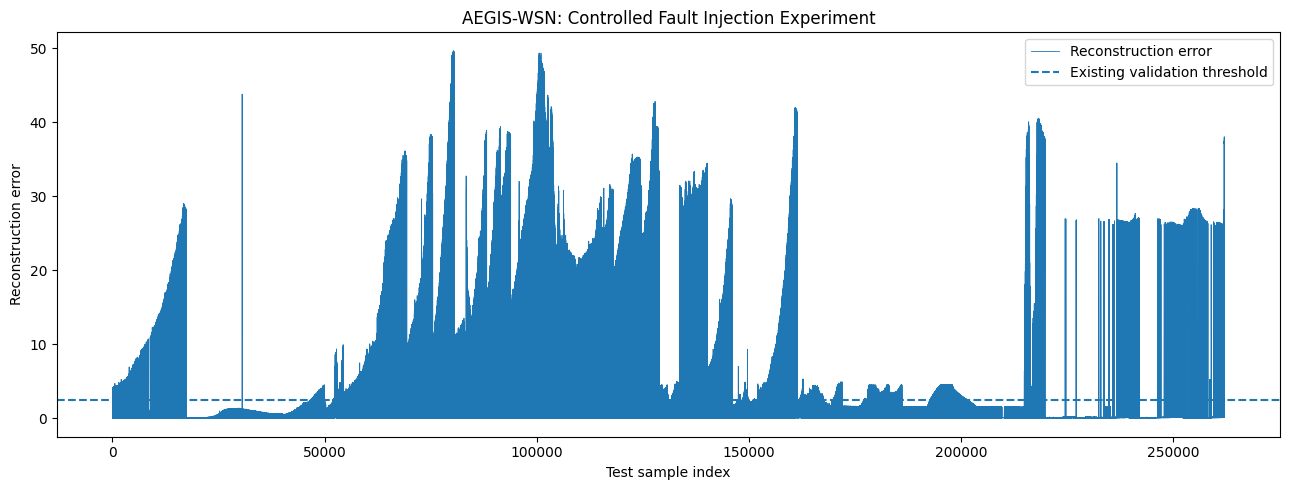

In [59]:

import matplotlib.pyplot as plt

plt.figure(figsize=(13, 5))

plt.plot(experiment_scores, linewidth=0.6, label="Reconstruction error")
plt.axhline(
    threshold,
    linestyle="--",
    label="Existing validation threshold"
)

plt.xlabel("Test sample index")
plt.ylabel("Reconstruction error")
plt.title("AEGIS-WSN: Controlled Fault Injection Experiment")
plt.legend()
plt.tight_layout()
plt.show()


In [60]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

fault_type_labels = np.full(len(y_true), "normal", dtype=object)

for fault_type, (start, end) in fault_types.items():
    fault_type_labels[start:end] = fault_type

rows = []

for fault_type in fault_types:
    mask = fault_type_labels == fault_type
    actual = np.asarray(y_true)[mask]
    predicted = np.asarray(y_pred)[mask]

    rows.append({
        "fault_type": fault_type,
        "samples": int(mask.sum()),
        "detected": int(((actual == 1) & (predicted == 1)).sum()),
        "missed": int(((actual == 1) & (predicted == 0)).sum()),
        "precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "f1_score": f1_score(
            actual, predicted, zero_division=0
        )
    })

fault_report = pd.DataFrame(rows)
display(fault_report.round(4))

,fault_type,samples,detected,missed,precision,recall,f1_score
0,spike,500,436,64,1.0,0.872,0.9316
1,drift,500,194,306,1.0,0.388,0.5591
2,stuck,500,30,470,1.0,0.060,0.1132
3,missing,500,0,500,0.0,0.000,0.0000


In [61]:
# Checking the original test data Before imputation.
sensor_cols = ["temperature", "humidity", "light", "voltage"]

print("Missing values in raw test data:")
display(df_test_raw[sensor_cols].isna().sum())

print("\nMissing values in the cleaned test data:")
display(df_test_clean[sensor_cols].isna().sum())

Missing values in raw test data:


temperature      73
humidity         73
light          6597
voltage           0
dtype: int64


Missing values in the cleaned test data:


temperature    0
humidity       0
light          0
voltage        0
dtype: int64

In [62]:
# Examine the injected stuck-at segment.
start, end = fault_types["stuck"]

stuck_segment = df_test_clean.iloc[start:end]

print("Rows in stuck segment:", len(stuck_segment))
print("\nUnique values per sensor:")
display(stuck_segment[sensor_cols].nunique())

Rows in stuck segment: 500

Unique values per sensor:


temperature    24
humidity       84
light          16
voltage        12
dtype: int64

In [63]:
# Comparing the injected segment with the original raw test data.
start, end = fault_types["stuck"]
print("Injected segment: ")
display(df_test_clean.iloc[start:start + 10][sensor_cols])
print("\nOriginal raw test segment: ")
display(df_test_raw.iloc[start:start + 10][sensor_cols])
print("\nUnique values in the injected segment: ")
display(df_test_clean.iloc[start:end][sensor_cols].nunique())

Injected segment: 


,temperature,humidity,light,voltage
943717,21.8210,36.4052,41.40,2.17553
943718,21.8210,39.4162,37.72,2.19970
943719,21.8210,39.4162,60.72,2.19970
943720,21.8210,39.4162,93.84,2.19970
943721,21.8210,39.4162,37.72,2.19970
943722,21.8210,39.4162,57.04,2.20788
943723,21.8210,39.4162,158.24,2.19159
943724,21.8210,39.4162,53.36,2.19970
943725,21.8210,39.4162,121.44,2.18353
943726,65.3722,52.7150,114.08,2.32000



Original raw test segment: 


,temperature,humidity,light,voltage
943717,122.1530,36.40520,41.40,2.17553
943718,122.1530,-3.91901,37.72,2.19970
943719,122.1530,-3.91901,60.72,2.19970
943720,122.1530,-3.91901,93.84,2.19970
943721,122.1530,-3.91901,37.72,2.19970
943722,122.1530,-3.91901,57.04,2.20788
943723,122.1530,-3.91901,158.24,2.19159
943724,122.1530,-3.75710,53.36,2.19970
943725,122.1530,-3.91901,121.44,2.18353
943726,65.3722,52.71500,114.08,2.32000



Unique values in the injected segment: 


temperature    24
humidity       84
light          16
voltage        12
dtype: int64

In [64]:
# Preserving the original missing value indicators
missing_flags = df_test_raw[sensor_cols].isna().copy()

print("Original missing readings by sensor:")
display(missing_flags.sum())

print("\nRows with at least one missing reading:",
      int(missing_flags.any(axis=1).sum()))

Original missing readings by sensor:


temperature      73
humidity         73
light          6597
voltage           0
dtype: int64


Rows with at least one missing reading: 6597


In [67]:
import numpy as np
import pandas as pd

start, end = fault_types["stuck"]

stuck_array = X_experiment[start:end]

print("Stuck segment shape:", stuck_array.shape)
print("\nUnique values per feature in scaled space:")

for i, feature in enumerate(sensor_cols):
    print(f"{feature}: {np.unique(stuck_array[:, i]).size}")

print("\nFirst 10 rows:")
display(pd.DataFrame(stuck_array[:10], columns=sensor_cols))

Stuck segment shape: (500, 4)

Unique values per feature in scaled space:
temperature: 24
humidity: 84
light: 1
voltage: 12

First 10 rows:


,temperature,humidity,light,voltage
0,-0.097933,-0.292954,-0.625003,-3.424013
1,-0.097933,0.120487,-0.625003,-3.216219
2,-0.097933,0.120487,-0.625003,-3.216219
3,-0.097933,0.120487,-0.625003,-3.216219
4,-0.097933,0.120487,-0.625003,-3.216219
5,-0.097933,0.120487,-0.625003,-3.145894
6,-0.097933,0.120487,-0.625003,-3.285942
7,-0.097933,0.120487,-0.625003,-3.216219
8,-0.097933,0.120487,-0.625003,-3.355235
9,10.243052,1.946549,-0.625003,-2.181978


In [68]:
print("Fault segments:", fault_types)
print("Experiment array shape:", X_experiment.shape)
print("Labels shape:", y_true.shape)

start, end = fault_types["stuck"]

print("\nLabels in stuck segment:")
print(np.unique(y_true[start:end], return_counts=True))

print("\nFeature ranges within stuck segment:")
print(pd.DataFrame(X_experiment[start:end], columns=sensor_cols).agg(["min", "max", "std"]).T)

Fault segments: {'spike': (52428, 52928), 'drift': (104857, 105357), 'stuck': (157286, 157786), 'missing': (209715, 210215)}
Experiment array shape: (262144, 4)
Labels shape: (262144,)

Labels in stuck segment:
(array([1], dtype=int32), array([500]))

Feature ranges within stuck segment:
                  min        max       std
temperature -4.868190  11.771862  2.432039
humidity    -4.196626   1.955255  1.190177
light       -0.625003  -0.625003  0.000000
voltage     -3.956522  -2.181978  0.297649


In [69]:
start, end = fault_types["stuck"]

original_segment = X_test[start:end]
injected_segment = X_experiment[start:end]

print("Original test feature standard deviations:")
display(pd.Series(
    original_segment.std(axis=0),
    index=sensor_cols
).to_frame("std_before_injection"))

print("\nInjected segment feature standard deviations:")
display(pd.Series(
    injected_segment.std(axis=0),
    index=sensor_cols
).to_frame("std_after_injection"))

print("\nLight values in injected segment:")
print(np.unique(injected_segment[:, sensor_cols.index("light")]))

Original test feature standard deviations:


,std_before_injection
temperature,2.429606
humidity,1.188987
light,0.094163
voltage,0.297352



Injected segment feature standard deviations:


,std_after_injection
temperature,2.429602
humidity,1.188987
light,0.000002
voltage,0.297352



Light values in injected segment:
[-0.6250031]


In [70]:
import numpy as np
import pandas as pd

# Use the light feature from the experimental array.
light_values = X_experiment[:, sensor_cols.index("light")]

# Rolling windows of 20 readings.
window_size = 20
light_series = pd.Series(light_values)

rolling_std = light_series.rolling(
    window=window_size,
    min_periods=window_size
).std()

# A very small standard deviation indicates a possible stuck sensor.
# This is a diagnostic threshold, not a final calibrated setting.
stuck_candidates = rolling_std < 1e-4

start, end = fault_types["stuck"]
injected_mask = np.zeros(len(X_experiment), dtype=bool)
injected_mask[start:end] = True

valid = rolling_std.notna()

print("Window size:", window_size)
print("Candidate stuck readings:", int(stuck_candidates.sum()))
print(
    "Injected stuck readings flagged:",
    int((stuck_candidates & injected_mask & valid).sum()),
    "out of", int((injected_mask & valid).sum())
)
print(
    "Candidate readings outside injected segment:",
    int((stuck_candidates & ~injected_mask & valid).sum())
)

Window size: 20
Candidate stuck readings: 977
Injected stuck readings flagged: 481 out of 500
Candidate readings outside injected segment: 496


In [71]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)
import numpy as np

# The rolling detector's output
temporal_pred = stuck_candidates.fillna(False).to_numpy().astype(int)

# Positive class: only the injected stuck-at interval
stuck_true = np.zeros(len(X_experiment), dtype=int)
start, end = fault_types["stuck"]
stuck_true[start:end] = 1

print("Confusion matrix [normal/non-stuck, stuck-at]:")
print(confusion_matrix(stuck_true, temporal_pred))

print("\nClassification report:")
print(classification_report(
    stuck_true,
    temporal_pred,
    target_names=["Non-stuck", "Stuck-at"],
    zero_division=0
))

Confusion matrix [normal/non-stuck, stuck-at]:
[[261148    496]
 [    19    481]]

Classification report:
              precision    recall  f1-score   support

   Non-stuck       1.00      1.00      1.00    261644
    Stuck-at       0.49      0.96      0.65       500

    accuracy                           1.00    262144
   macro avg       0.75      0.98      0.83    262144
weighted avg       1.00      1.00      1.00    262144



In [72]:
from sklearn.metrics import precision_score, recall_score, f1_score

# autoencoder predictions
ae_pred = np.asarray(y_pred).astype(int)

#  temporal predictions
temp_pred = stuck_candidates.fillna(False).to_numpy().astype(int)

# Ground truth: only the injected stuck-at segment
stuck_true = np.zeros(len(X_experiment), dtype=int)
start, end = fault_types["stuck"]
stuck_true[start:end] = 1

# OR fusion: flag if either detector raises an alert
combined_pred = ((ae_pred == 1) | (temp_pred == 1)).astype(int)

def report_metrics(name, y_true, y_hat):
    print(
        f"{name:20s}",
        f"Precision={precision_score(y_true, y_hat, zero_division=0):.3f}",
        f"Recall={recall_score(y_true, y_hat, zero_division=0):.3f}",
        f"F1={f1_score(y_true, y_hat, zero_division=0):.3f}"
    )

report_metrics("Autoencoder", stuck_true, ae_pred)
report_metrics("Temporal", stuck_true, temp_pred)
report_metrics("Combined OR", stuck_true, combined_pred)

Autoencoder          Precision=0.001 Recall=0.060 F1=0.002
Temporal             Precision=0.492 Recall=0.962 F1=0.651
Combined OR          Precision=0.017 Recall=0.964 F1=0.034


In [73]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

light_values = X_experiment[:, sensor_cols.index("light")]

window_size = 20
light_series = pd.Series(light_values)

rolling_std = light_series.rolling(
    window=window_size,
    min_periods=window_size
).std()

# Candidate windows: nearly constant light readings
candidate = (rolling_std < 1e-4).fillna(False)

# Require 3 consecutive candidate windows
persistence_windows = 3
persistent_stuck = (
    candidate.astype(int)
    .rolling(persistence_windows, min_periods=persistence_windows)
    .sum()
    .eq(persistence_windows)
    .to_numpy()
)

# Ground truth: injected stuck-at interval
stuck_true = np.zeros(len(X_experiment), dtype=int)
start, end = fault_types["stuck"]
stuck_true[start:end] = 1

print("Persistence windows:", persistence_windows)
print("Precision:", round(
    precision_score(stuck_true, persistent_stuck, zero_division=0), 4
))
print("Recall:", round(
    recall_score(stuck_true, persistent_stuck, zero_division=0), 4
))
print("F1-score:", round(
    f1_score(stuck_true, persistent_stuck, zero_division=0), 4
))
print("False positives:", int(
    ((persistent_stuck == 1) & (stuck_true == 0)).sum()
))

Persistence windows: 3
Precision: 0.4933
Recall: 0.958
F1-score: 0.6513
False positives: 492


In [74]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

# Temporal detector using rolling standard deviation.
# For this initial comparison, use the original 20-reading rule.
temporal_pred = stuck_candidates.fillna(False).to_numpy().astype(int)

rows = []

for fault_type, (start, end) in fault_types.items():
    # Ground truth for this fault type only
    y_fault = np.zeros(len(X_experiment), dtype=int)
    y_fault[start:end] = 1

    rows.append({
        "fault_type": fault_type,
        "injected_samples": int((y_fault == 1).sum()),
        "detected": int(((y_fault == 1) & (temporal_pred == 1)).sum()),
        "missed": int(((y_fault == 1) & (temporal_pred == 0)).sum()),
        "precision": precision_score(
            y_fault, temporal_pred, zero_division=0
        ),
        "recall": recall_score(
            y_fault, temporal_pred, zero_division=0
        ),
        "f1_score": f1_score(
            y_fault, temporal_pred, zero_division=0
        )
    })

temporal_report = pd.DataFrame(rows)
display(temporal_report.round(4))

,fault_type,injected_samples,detected,missed,precision,recall,f1_score
0,spike,500,0,500,0.0000,0.000,0.0000
1,drift,500,0,500,0.0000,0.000,0.0000
2,stuck,500,481,19,0.4923,0.962,0.6513
3,missing,500,481,19,0.4923,0.962,0.6513


In [75]:
# Inspect the injected missing segment in scaled space.
start, end = fault_types["missing"]
missing_array = X_experiment[start:end]

print("Missing segment shape:", missing_array.shape)
print("\nNaN count per feature:")
display(pd.Series(
    np.isnan(missing_array).sum(axis=0),
    index=sensor_cols
))

print("\nInfinite count per feature:")
display(pd.Series(
    np.isinf(missing_array).sum(axis=0),
    index=sensor_cols
))

print("\nUnique values per feature:")
display(pd.Series(
    [np.unique(missing_array[:, i]).size
     for i in range(missing_array.shape[1])],
    index=sensor_cols
))

Missing segment shape: (500, 4)

NaN count per feature:


temperature    0
humidity       0
light          0
voltage        0
dtype: int64


Infinite count per feature:


temperature    0
humidity       0
light          0
voltage        0
dtype: int64


Unique values per feature:


temperature    1
humidity       1
light          1
voltage        1
dtype: int64

In [76]:
import numpy as np
import pandas as pd

# Start from the original scaled test data.
X_missing_experiment = X_test.copy()

# Use the existing missing-fault segment.
start, end = fault_types["missing"]

# Inject missing readings into the light sensor only.
light_idx = sensor_cols.index("light")
X_missing_experiment[start:end, light_idx] = np.nan

# Ground-truth labels: 1 = deliberately injected missing reading.
y_missing_true = np.zeros(len(X_missing_experiment), dtype=int)
y_missing_true[start:end] = 1

# Verify the injection.
print("Injected rows:", end - start)
print("Missing light readings:",
      np.isnan(X_missing_experiment[:, light_idx]).sum())
print("Missing readings in other features:")
print(np.isnan(X_missing_experiment).sum(axis=0))

print("Ground-truth labels:")
print(pd.Series(y_missing_true).value_counts().sort_index())

Injected rows: 500
Missing light readings: 500
Missing readings in other features:
[  0   0 500   0]
Ground-truth labels:
0    261644
1       500
Name: count, dtype: int64


In [77]:
# Detect any missing sensor feature before imputation.
missing_pred = np.isnan(X_missing_experiment).any(axis=1).astype(int)

from sklearn.metrics import classification_report, confusion_matrix

print("Confusion matrix:")
print(confusion_matrix(y_missing_true, missing_pred))

print("\nClassification report:")
print(classification_report(
    y_missing_true,
    missing_pred,
    target_names=["Normal", "Injected missing"],
    zero_division=0
))

Confusion matrix:
[[261644      0]
 [     0    500]]

Classification report:
                  precision    recall  f1-score   support

          Normal       1.00      1.00      1.00    261644
Injected missing       1.00      1.00      1.00       500

        accuracy                           1.00    262144
       macro avg       1.00      1.00      1.00    262144
    weighted avg       1.00      1.00      1.00    262144



In [78]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

# Predictions from the existing autoencoder
ae_pred = np.asarray(y_pred).astype(int)

# Temporal detector for stuck-light faults
temporal_pred = stuck_candidates.fillna(False).to_numpy().astype(int)

# Explicit missingness detector on the separate missing experiment
missing_pred = np.asarray(missing_pred).astype(int)

results = []

for fault_type, (start, end) in fault_types.items():
    y_fault = np.zeros(len(X_experiment), dtype=int)
    y_fault[start:end] = 1

    # Select the appropriate detector for this fault type.
    if fault_type == "stuck":
        pred = temporal_pred
    elif fault_type == "missing":
        # Evaluate only against the matching missingness experiment.
        y_eval = y_missing_true
        pred_eval = missing_pred
        results.append({
            "fault_type": fault_type,
            "detector": "Missingness rule",
            "precision": precision_score(y_eval, pred_eval, zero_division=0),
            "recall": recall_score(y_eval, pred_eval, zero_division=0),
            "f1": f1_score(y_eval, pred_eval, zero_division=0)
        })
        continue
    else:
        pred = ae_pred

    results.append({
        "fault_type": fault_type,
        "detector": "Autoencoder" if fault_type != "stuck" else "Temporal rule",
        "precision": precision_score(y_fault, pred, zero_division=0),
        "recall": recall_score(y_fault, pred, zero_division=0),
        "f1": f1_score(y_fault, pred, zero_division=0)
    })

display(pd.DataFrame(results).round(4))

,fault_type,detector,precision,recall,f1
0,spike,Autoencoder,0.0163,0.872,0.0320
1,drift,Autoencoder,0.0073,0.388,0.0143
2,stuck,Temporal rule,0.4923,0.962,0.6513
3,missing,Missingness rule,1.0000,1.000,1.0000


# AEGIS-WSN decision layer(prototype decision layer)

In [79]:
import numpy as np
import pandas as pd

# Start with the existing autoencoder predictions.
ae_pred = np.asarray(y_pred).astype(bool)

# Existing temporal stuck-light detector.
temporal_pred = stuck_candidates.fillna(False).to_numpy().astype(bool)

# Missingness evidence from the separate controlled experiment.
missing_pred = np.asarray(missing_pred).astype(bool)

# Evidence flags are kept separate rather than blindly OR-ing them.
decision_df = pd.DataFrame({
    "autoencoder_alert": ae_pred,
    "temporal_stuck_candidate": temporal_pred,
    "missing_reading": missing_pred
})

# Transparent provisional response states.
decision_df["response_state"] = np.select(
    [
        decision_df["missing_reading"],
        decision_df["temporal_stuck_candidate"],
        decision_df["autoencoder_alert"]
    ],
    [
        "VERIFY_MISSING",
        "VERIFY_STUCK",
        "WATCH_ANOMALY"
    ],
    default="NORMAL"
)

display(decision_df["response_state"].value_counts().to_frame("samples"))

,samples
response_state,
NORMAL,234464
WATCH_ANOMALY,26684
VERIFY_MISSING,500
VERIFY_STUCK,496


In [80]:
from pathlib import Path
import json
import pandas as pd

output_dir = Path("../results")
output_dir.mkdir(exist_ok=True)

# Saving the preliminary fault comparison.
pd.DataFrame(results).to_csv(
    output_dir / "preliminary_fault_results.csv",
    index=False
)

# Saving the current response-state counts.
decision_df["response_state"].value_counts().rename_axis(
    "response_state"
).reset_index(name="samples").to_csv(
    output_dir / "response_state_counts.csv",
    index=False
)

# Saving key experimental settings and caveats.
baseline_notes = {
    "project": "AEGIS-WSN",
    "dataset": "Intel Berkeley Lab sensor readings",
    "model": "Dense autoencoder",
    "fault_types": ["spike", "drift", "stuck-at", "missing"],
    "status": "Preliminary controlled experiments",
    "limitations": [
        "Fault injections require further validation",
        "Temporal detector has false positives",
        "Missingness detector was tested separately",
        "Combined response states are not yet validated"
    ]
}

(output_dir / "baseline_notes.json").write_text(
    json.dumps(baseline_notes, indent=2)
)

print("Saved preliminary results to:", output_dir.resolve())
print("Files:", sorted(p.name for p in output_dir.iterdir()))

Saved preliminary results to: C:\Users\arsha\Desktop\capstone\results
Files: ['baseline_notes.json', 'preliminary_fault_results.csv', 'response_state_counts.csv']


In [81]:

import numpy as np
import pandas as pd

# Start from the original scaled test array.
X_eval = X_test.copy()
n_samples, n_features = X_eval.shape

# 0 = normal; 1 = spike; 2 = drift; 3 = stuck; 4 = missing
y_eval = np.zeros(n_samples, dtype=np.int32)

fault_types_eval = {
    "spike": (50000, 50500),
    "drift": (100000, 10500 + 100000),
    "stuck": (150000, 150500),
    "missing": (200000, 200500)
}

# Keep a copy of the untouched data for comparison.
X_eval_original = X_eval.copy()

rng = np.random.default_rng(42)

# 1. Spike: add a large deviation to temperature.
start, end = fault_types_eval["spike"]
X_eval[start:end, 0] += 6.0
y_eval[start:end] = 1

# 2. Drift: gradually increase temperature.
start, end = fault_types_eval["drift"]
X_eval[start:end, 0] += np.linspace(0.0, 5.0, end - start)
y_eval[start:end] = 2

# 3. Stuck: hold the light feature constant.
start, end = fault_types_eval["stuck"]
X_eval[start:end, 2] = X_eval[start, 2]
y_eval[start:end] = 3

# 4. Missing: set light readings to NaN.
start, end = fault_types_eval["missing"]
X_eval[start:end, 2] = np.nan
y_eval[start:end] = 4

print("Evaluation shape:", X_eval.shape)
print("\nLabels:")
display(pd.Series(y_eval).value_counts().sort_index())

print("\nNaN counts per feature:")
display(pd.Series(
    np.isnan(X_eval).sum(axis=0),
    index=sensor_cols
))


Evaluation shape: (262144, 4)

Labels:


0    250144
1       500
2     10500
3       500
4       500
Name: count, dtype: int64


NaN counts per feature:


temperature      0
humidity         0
light          500
voltage          0
dtype: int64

In [82]:
start, end = 100000, 100500

X_eval[start:end] = X_eval_original[start:end]

X_eval[start:end, 0] += np.linspace(0.0, 5.0, end - start)

y_eval[start:end] = 2
print("Corrected labels:")
display(pd.Series(y_eval).value_counts().sort_index())

print("\nFault intervals:")
print(fault_types_eval)

Corrected labels:


0    250144
1       500
2     10500
3       500
4       500
Name: count, dtype: int64


Fault intervals:
{'spike': (50000, 50500), 'drift': (100000, 110500), 'stuck': (150000, 150500), 'missing': (200000, 200500)}


In [83]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

print("Label counts:")
display(pd.Series(y_eval).value_counts().sort_index())

missing_mask = np.isnan(X_eval).any(axis=1)

X_eval_model = np.nan_to_num(
    X_eval.copy(),
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

eval_reconstructed = autoencoder.predict(
    X_eval_model, verbose=0
)
eval_scores = np.mean(
    np.square(X_eval_model - eval_reconstructed),
    axis=1
)

ae_eval_pred = (eval_scores > threshold).astype(int)

print("\nAutoencoder score shape:", eval_scores.shape)
print("Missing rows preserved:", int(missing_mask.sum()))
print("Threshold:", float(threshold))

Label counts:


0    250144
1       500
2     10500
3       500
4       500
Name: count, dtype: int64


Autoencoder score shape: (262144,)
Missing rows preserved: 500
Threshold: 2.485562801361084


In [84]:
fault_names = {
    1: "Spike",
    2: "Drift",
    3: "Stuck-at",
    4: "Missing"
}

rows = []

for label, name in fault_names.items():
    y_binary = (y_eval == label).astype(int)

    rows.append({
        "fault_type": name,
        "precision": precision_score(
            y_binary, ae_eval_pred, zero_division=0
        ),
        "recall": recall_score(
            y_binary, ae_eval_pred, zero_division=0
        ),
        "f1_score": f1_score(
            y_binary, ae_eval_pred, zero_division=0
        ),
        "detected": int(
            ((y_binary == 1) & (ae_eval_pred == 1)).sum()
        ),
        "injected": int(y_binary.sum())
    })

display(pd.DataFrame(rows).round(4))

,fault_type,precision,recall,f1_score,detected,injected
0,Spike,0.0163,0.900,0.0319,450,500
1,Drift,0.1604,0.423,0.2326,4442,10500
2,Stuck-at,0.0000,0.002,0.0001,1,500
3,Missing,0.0000,0.000,0.0000,0,500


In [85]:
# Confirm the current evaluation labels.
print("Evaluation dataset shape:", X_eval.shape)
print("\nLabel counts:")
display(
    pd.Series(y_eval)
    .value_counts()
    .sort_index()
    .rename_axis("label")
    .to_frame("samples")
)

print("\nFault intervals:")
for name, (start, end) in fault_types_eval.items():
    print(
        f"{name}: start={start}, end={end}, "
        f"length={end - start}"
    )

Evaluation dataset shape: (262144, 4)

Label counts:


,samples
label,
0,250144
1,500
2,10500
3,500
4,500



Fault intervals:
spike: start=50000, end=50500, length=500
drift: start=100000, end=110500, length=10500
stuck: start=150000, end=150500, length=500
missing: start=200000, end=200500, length=500


In [86]:

import numpy as np
import pandas as pd

# Start fresh from the untouched test data.
X_eval = X_test.copy()
X_eval_original = X_test.copy()

n_samples = len(X_eval)

# Separate 500-row intervals.
fault_types_eval = {
    "spike":   (50000, 50500),
    "drift":   (100000, 100500),
    "stuck":   (150000, 150500),
    "missing": (200000, 200500)
}

# 0 = normal, 1 = spike, 2 = drift, 3 = stuck, 4 = missing
y_eval = np.zeros(n_samples, dtype=np.int32)

# Spike: sudden temperature increase.
s, e = fault_types_eval["spike"]
X_eval[s:e, 0] += 6.0
y_eval[s:e] = 1

# Drift: gradual temperature increase over exactly 500 rows.
s, e = fault_types_eval["drift"]
X_eval[s:e, 0] += np.linspace(0.0, 5.0, e - s)
y_eval[s:e] = 2

# Stuck-at: light sensor stops changing.
s, e = fault_types_eval["stuck"]
X_eval[s:e, 2] = X_eval[s, 2]
y_eval[s:e] = 3

# Missing: preserve 500 actual NaNs in the light feature.
s, e = fault_types_eval["missing"]
X_eval[s:e, 2] = np.nan
y_eval[s:e] = 4

# Verify the intervals and labels.
print("Fault interval lengths:")
for name, (s, e) in fault_types_eval.items():
    print(f"{name}: {e - s}")

print("\nLabel counts:")
display(
    pd.Series(y_eval)
    .value_counts()
    .sort_index()
    .rename_axis("label")
    .to_frame("samples")
)

print("\nNaNs per feature:")
display(pd.Series(
    np.isnan(X_eval).sum(axis=0),
    index=sensor_cols
))


Fault interval lengths:
spike: 500
drift: 500
stuck: 500
missing: 500

Label counts:


,samples
label,
0,260144
1,500
2,500
3,500
4,500



NaNs per feature:


temperature      0
humidity         0
light          500
voltage          0
dtype: int64

In [87]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

# Preserve missingness before preparing model input.
missing_mask_eval = np.isnan(X_eval).any(axis=1)
X_eval_model = np.nan_to_num(
    X_eval.copy(),
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

eval_reconstructed = autoencoder.predict(
    X_eval_model, verbose=0
)

eval_scores = np.mean(
    (X_eval_model - eval_reconstructed) ** 2,
    axis=1
)

ae_eval_pred = (eval_scores > threshold).astype(int)

fault_names = {
    1: "Spike",
    2: "Drift",
    3: "Stuck-at",
    4: "Missing"
}

rows = []

for label, name in fault_names.items():
    y_binary = (y_eval == label).astype(int)

    rows.append({
        "fault_type": name,
        "injected": int(y_binary.sum()),
        "detected": int(
            ((y_binary == 1) & (ae_eval_pred == 1)).sum()
        ),
        "precision": precision_score(
            y_binary, ae_eval_pred, zero_division=0
        ),
        "recall": recall_score(
            y_binary, ae_eval_pred, zero_division=0
        ),
        "f1_score": f1_score(
            y_binary, ae_eval_pred, zero_division=0
        )
    })

display(pd.DataFrame(rows).round(4))

print("Missing rows preserved:", int(missing_mask_eval.sum()))
print("Validation threshold:", float(threshold))

,fault_type,injected,detected,precision,recall,f1_score
0,Spike,500,450,0.0168,0.900,0.0331
1,Drift,500,273,0.0102,0.546,0.0201
2,Stuck-at,500,1,0.0000,0.002,0.0001
3,Missing,500,0,0.0000,0.000,0.0000


Missing rows preserved: 500
Validation threshold: 2.485562801361084


In [88]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

# Existing autoencoder predictions
ae_pred = np.asarray(ae_eval_pred).astype(bool)

# Temporal rule: rolling standard deviation of light
light_idx = sensor_cols.index("light")
light_series = pd.Series(X_eval[:, light_idx])

rolling_std_eval = light_series.rolling(
    window=20, min_periods=20
).std()

stuck_pred = (rolling_std_eval < 1e-4).fillna(False).to_numpy()

# Missingness rule: check before replacing NaNs
missing_pred_eval = np.isnan(X_eval).any(axis=1)

# Evaluate each detector only against its corresponding fault type
fault_labels = {
    "Stuck-at": (y_eval == 3),
    "Missing": (y_eval == 4)
}

predictions = {
    "Autoencoder": ae_pred,
    "Temporal rule": stuck_pred,
    "Missingness rule": missing_pred_eval
}

rows = []

for fault_name, truth in fault_labels.items():
    for detector_name, pred in predictions.items():
        # Each comparison is one fault type versus all other samples.
        rows.append({
            "fault_type": fault_name,
            "detector": detector_name,
            "precision": precision_score(truth, pred, zero_division=0),
            "recall": recall_score(truth, pred, zero_division=0),
            "f1_score": f1_score(truth, pred, zero_division=0)
        })

display(pd.DataFrame(rows).round(4))

,fault_type,detector,precision,recall,f1_score
0,Stuck-at,Autoencoder,0.0000,0.002,0.0001
1,Stuck-at,Temporal rule,0.9698,0.962,0.9659
2,Stuck-at,Missingness rule,0.0000,0.000,0.0000
3,Missing,Autoencoder,0.0000,0.000,0.0000
4,Missing,Temporal rule,0.0000,0.000,0.0000
5,Missing,Missingness rule,1.0000,1.000,1.0000


In [89]:
import numpy as np
from sklearn.metrics import confusion_matrix

# Autoencoder predictions from the corrected evaluation
normal_mask = (y_eval == 0)

normal_actual = np.zeros(normal_mask.sum(), dtype=int)
normal_pred = np.asarray(ae_eval_pred)[normal_mask].astype(int)

tn = int((normal_pred == 0).sum())
fp = int((normal_pred == 1).sum())

print("Normal samples:", int(normal_mask.sum()))
print("False positives:", fp)
print("True negatives:", tn)
print("False-positive rate:", round(fp / (fp + tn), 4))

Normal samples: 260144
False positives: 25999
True negatives: 234145
False-positive rate: 0.0999
